# Summary Report

## Import Libraries & Data

In [2]:
import pandas as pd
import numpy as np

swd = "lab5"
data = pd.read_csv("../Results/analytic_table.csv")
lab3_sample = data.head(5)
lab4_sample = data.tail(5)
print(lab3_sample)

  sample_id patient_name         dob sex enrollment_site glucose_value  \
0     S0001    A. Nguyen  1962/07/09   F               A          75.4   
1     S0002     T. Patel  1974/12/16   M               A         120.0   
2     S0003  R. Martinez  2053/11/24   F               B          84.2   
3     S0004     B. Smith  1975/12/18   F               B         120.0   
4     S0005  B. Martinez  1997/12/02   M               A         248.1   

  glucose_unit notes source patient_id  age_at_diagnosis stage  \
0        mg/dl   NaN   Lab3        NaN               NaN   NaN   
1        mg/dl   NaN   Lab3        NaN               NaN   NaN   
2        mg/dl   NaN   Lab3        NaN               NaN   NaN   
3        mg/dl   NaN   Lab3        NaN               NaN   NaN   
4        mg/dl   NaN   Lab3        NaN               NaN   NaN   

  tissue_source_site  tmb_nonsynonymous  EGFR  KEAP1  KRAS  STK11  TP53  
0                NaN                NaN   NaN    NaN   NaN    NaN   NaN  
1         

In [19]:
print(lab4_sample)

    sample_id patient_name  dob     sex enrollment_site glucose_value  \
621       NaN          NaN  NaN  female             NaN           NaN   
622       NaN          NaN  NaN    male             NaN           NaN   
623       NaN          NaN  NaN    male             NaN           NaN   
624       NaN          NaN  NaN  female             NaN           NaN   
625       NaN          NaN  NaN  female             NaN           NaN   

    glucose_unit notes source    patient_id  age_at_diagnosis stage  \
621          NaN   NaN   Lab4  TCGA-NJ-A55O              56.0   IIA   
622          NaN   NaN   Lab4  TCGA-NJ-A55R              67.0    IA   
623          NaN   NaN   Lab4  TCGA-NJ-A7XG              49.0  IIIA   
624          NaN   NaN   Lab4  TCGA-O1-A52J              74.0    IA   
625          NaN   NaN   Lab4  TCGA-S2-AA1A              68.0    IA   

                          tissue_source_site  tmb_nonsynonymous  EGFR  KEAP1  \
621  Washington University - Rush University          

## Table Info & Data Type

In [6]:
print("Total rows:", len(data))
print("Total columns:", len(data.columns))
print(data.dtypes)

data[["glucose_value","age_at_diagnosis", "EGFR", "KEAP1", "KRAS", "STK11", "TP53"]] = data[["glucose_value","age_at_diagnosis", "EGFR", "KEAP1", "KRAS", "STK11", "TP53"]].apply(pd.to_numeric, errors="coerce")
print(data.dtypes)

Total rows: 626
Total columns: 19
sample_id              object
patient_name           object
dob                    object
sex                    object
enrollment_site        object
glucose_value          object
glucose_unit           object
notes                  object
source                 object
patient_id             object
age_at_diagnosis      float64
stage                  object
tissue_source_site     object
tmb_nonsynonymous     float64
EGFR                  float64
KEAP1                 float64
KRAS                  float64
STK11                 float64
TP53                  float64
dtype: object
sample_id              object
patient_name           object
dob                    object
sex                    object
enrollment_site        object
glucose_value         float64
glucose_unit           object
notes                  object
source                 object
patient_id             object
age_at_diagnosis      float64
stage                  object
tissue_source_site    

## Quick Descriptive Report

### Lab3 Related Data

In [37]:
data.groupby("sex")["glucose_value"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
sex,,,,
F,16,157.212500,145.8,50.986990
M,23,173.252174,176.9,52.673047
female,0,NaN,NaN,NaN
male,0,NaN,NaN,NaN


### Lab 4 Related Data

In [38]:
data.groupby("sex")[["TP53","STK11","KEAP1","EGFR"]].agg(["count", "mean", "median", "std"])

TP53                            STK11                             \
       count      mean median       std count      mean median       std   
sex                                                                        
F          0       NaN    NaN       NaN     0       NaN    NaN       NaN   
M          0       NaN    NaN       NaN     0       NaN    NaN       NaN   
female   135  1.044444    1.0  0.206848    30  1.000000    1.0  0.000000   
male     122  1.081967    1.0  0.275446    44  1.159091    1.0  0.369989   

       KEAP1                            EGFR                         
       count     mean median       std count  mean median       std  
sex                                                                  
F          0      NaN    NaN       NaN     0   NaN    NaN       NaN  
M          0      NaN    NaN       NaN     0   NaN    NaN       NaN  
female    41  1.02439    1.0  0.156174    45  1.20    1.0  0.457265  
male      54  1.00000    1.0  0.000000    20  1.35    1.0  0.587143

## Quick Figures

### Lab3 Related Data

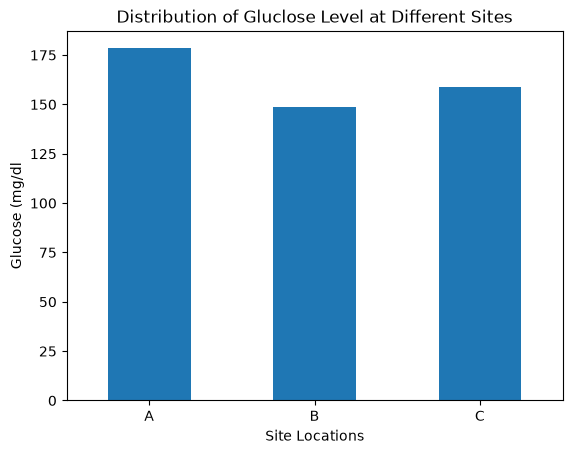

In [13]:
import matplotlib.pyplot as plt

enrolment_glucose = data.groupby("enrollment_site")["glucose_value"].mean()
    
enrolment_glucose.plot(kind="bar")
plt.title("Distribution of Gluclose Level at Different Sites")
plt.xlabel("Site Locations")
plt.ylabel("Glucose (mg/dl")
plt.xticks(rotation=0)
plt.show()

### Lab 4 Related Data

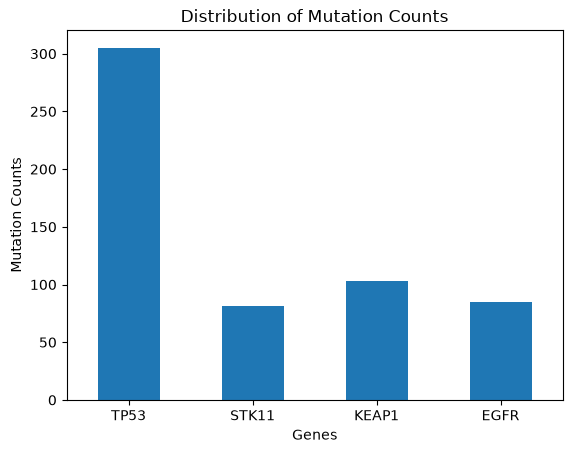

In [14]:
import matplotlib.pyplot as plt

genes = ["TP53", "STK11", "KEAP1", "EGFR"]

mutation_counts = data[genes].sum()

mutation_counts.plot(kind="bar")

plt.title("Distribution of Mutation Counts")
plt.xlabel("Genes")
plt.ylabel("Mutation Counts")
plt.xticks(rotation=0)
plt.show()

## General Summary

To wrap up the summary report, the analytic table found that for patients who attended sites with recorded glucose levels, 23 males had tests compared to 16. It found that male (mean = 173, sd = 52) had higher glucose levels comapred to females (mean = 157, sd = 50). When looking at the particular sites, of the total patients (N = 39), site A had recorded the highest glucose mean of its patients where site B had the lowest glucose means. These are descriptive, so further testing needs to be done to find the significance of these trends.

In the Lab 4 data from the analytic table, it was found that, among 566 patients, the TP53 mutation was the most prevalent across both genders (Female = 135, Male = 122). When looking at the bar chart visualization, this is also noticable, followed by KEAP1 (Female = 41, Male 54). Again to emphaise, these are descriptive and further testing is needed to find the signficance.

When combining both into one table, it made it easy to pull information. And more exciting, I had learn this method of developing a workflow. These two tables seem to have limited overlap in their data tables that prevents direct comparison, but I can see how Snakemake would be greatly beneficial if that was the case (especially as one script was made from R and another from Python). 